# Office domain CCS via the Option Keyboard (OKB)

Building this up step by step so each piece is understood before moving to the next, the
same way `RM/sf-fsa-vi/notebooks/office_ccs_results.ipynb` built up plain SFOLS/GPI on this
domain, and `OKB/notebooks/dst_okb_results.ipynb` built up OKB on Deep Sea Treasure. This one
combines both: OKB's algorithm (`OKB/rl/successor_features/okb.py`), applied to `Office-v0`
(`RM/sf-fsa-vi/envs/grid_envs.py`), to compute its CCS the paper's way (see the NeurIPS PDF
in `OKB/`).

Planned steps:
1. **Environment** (this notebook, for now): `Office-v0` and `OKB` come from two different,
   incompatible RL-env conventions -- bridge them with an adapter, and check it actually
   satisfies what `OKB` needs before trusting it with real training.
2. Base CCS via OLS + GPI (SFOLS-style; reuses OKB's own `rl/successor_features/ols.py`).
3. Train the Option Keyboard on top of the base CCS.
4. OK vs. GPI vs. single-policy utility comparison across preferences -- the paper's actual
   claim, made measurable.
5. Rollouts and visualization.

Run with the `okb` kernel.

In [109]:
import os
os.environ["WANDB_MODE"] = "disabled"  # OKB calls wandb.log/define_metric internally; no-ops these

import sys
OKB_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "RM", "sf-fsa-vi"))
for root in (OKB_ROOT, SF_FSA_VI_ROOT):
    if root not in sys.path:
        sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import wandb
wandb.init(mode="disabled")

# `Office-v0` is registered under old `gym` (RM/sf-fsa-vi/envs/__init__.py), while OKB is
# built on `gymnasium` -- both packages are installed side by side in the `okb` env
# specifically so this notebook can bridge them (see Section 1 below).
import gym as old_gym
import gymnasium as gym
from gymnasium import spaces
import envs  # noqa: F401 -- registers Office-v0 (and Delivery-v0, DoubleSlit-v0, ...) in old gym

from rl.successor_features.okb import OKB
from rl.successor_features.ols import OLS
from rl.utils.utils import seed_everything
from rl.utils.eval import policy_evaluation_mo

%matplotlib inline

## Config

In [110]:
SEED = 0
GAMMA = 0.99
ADD_OBJ_TO_START = True   # mirrors office_ccs_results.ipynb: register every object cell as a valid start state too
PHI_OBJ_TYPES = ["C1", "C2", "O1", "O2", "M1", "M2"]

seed_everything(SEED)

## 1. The compatibility problem: `Office-v0` (old `gym`) vs. `OKB` (`gymnasium`)

Checked directly against the actual code (not assumed) before writing any adapter:

- **API shape.** `Office.step()` (`grid_envs.py:144-158`) returns the old-gym 4-tuple
  `(obs, reward, done, info)`, and `reset()` (`grid_envs.py:109-114`) returns just `obs`.
  `OKB`'s training loop (`okb.py:1676-1793`) unconditionally unpacks the `gymnasium` 5-tuple
  `(obs, reward, terminated, truncated, info) = env.step(...)` and `(obs, info) = env.reset()`.
- **What "reward" means.** `Office.step()` returns a *scalar* `reward = -1` and buries the
  actual multi-objective signal in `info['phi']` (a one-hot indicator over the 6 predicates,
  `grid_envs.py:184-192`). `OKB` expects `env.step()` to hand back the **vector** reward
  directly (`okb.py:1688`: `next_obs, vec_reward, terminated, truncated, info = self.env.step(action)`,
  then stored straight into the replay buffer as the SF-learning target).
- **`reward_dim`.** `OKB.__init__` reads `self.env.unwrapped.reward_dim` (`okb.py:488`).
  Office instead exposes this as a `feat_dim` property (`grid_envs.py:194-196`) -- same
  number (6), different attribute name.
- **Space classes.** `RLAlgorithm.__init__` (`rl_algorithm.py:17`) does
  `isinstance(self.env.action_space, (spaces.Discrete, spaces.MultiBinary))` against
  **`gymnasium.spaces`**. Office's `action_space`/`observation_space` are old
  **`gym.spaces`** objects (`grid_envs.py:4,58-60`) -- a different class from a different
  package, so the `isinstance` check silently fails and `OKB` would try
  `action_space.shape[0]` on a `Discrete`, which has no meaningful shape and raises.

None of `OKB`'s own env wrappers (`rl/utils/wrappers.py`) fix this -- they're all old-gym
wrappers themselves, built for a different purpose (frame skipping, observation/reward
normalization). So the adapter below is a small `gymnasium.Env` that holds an `Office-v0`
instance internally and translates every one of the four mismatches above.

In [111]:
class OfficeGymnasiumEnv(gym.Env):
    """Wraps sf-fsa-vi's old-gym `Office-v0` so it satisfies OKB's gymnasium contract:
    5-tuple step/reset, gymnasium space classes, `reward_dim`/`reward_space`, and the
    per-feature vector `info['phi']` returned as the actual reward.
    """

    def __init__(self, add_obj_to_start=True, random_act_prob=0.0):
        self._env = old_gym.make("Office-v0", add_obj_to_start=add_obj_to_start, random_act_prob=random_act_prob)
        self.core = self._env.unwrapped  # the raw Office instance -- MAP, initial states, feat_dim, ...
        self.height, self.width = self.core.height, self.core.width

        self.action_space = spaces.Discrete(self.core.action_space.n)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32)

        self.reward_dim = self.core.feat_dim
        self.reward_space = spaces.Box(low=0.0, high=1.0, shape=(self.reward_dim,), dtype=np.float32)

    def _normalize(self, obs):
        # raw obs is (row, col) as integers; Box declares [0, 1], so normalize to match
        return np.array([obs[0] / (self.height - 1), obs[1] / (self.width - 1)], dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self._env.seed(seed)
        state = None if options is None else options.get("state")
        obs = self._env.reset(state=state)
        return self._normalize(obs), {}

    def step(self, action):
        obs, _scalar_reward, done, info = self._env.step(int(action))
        # old gym's TimeLimit wrapper (applied via gym.envs.register(max_episode_steps=200))
        # flags truncation this way instead of a separate return value
        truncated = info.pop("TimeLimit.truncated", False)
        terminated = bool(done) and not truncated
        reward = info["phi"].astype(np.float32)
        # `rl.utils.eval.eval_mo`/`policy_evaluation_mo` (used by SFOLS's GPI-based next_w,
        # Section 5 below) read the vector reward from `info["vector_reward"]`, not from the
        # return value -- populate it here too so those functions work directly with this env.
        info["vector_reward"] = reward
        return self._normalize(obs), reward, terminated, truncated, info


office_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
office_eval_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
print(f"action_space: {office_env.action_space}   observation_space: {office_env.observation_space}")
print(f"reward_dim: {office_env.reward_dim}   reward_space: {office_env.reward_space}")

action_space: Discrete(4)   observation_space: Box(0.0, 1.0, (2,), float32)
reward_dim: 6   reward_space: Box(0.0, 1.0, (6,), float32)


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment Office-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `Office-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


## 2. Sanity-check the adapter

Before handing this to `OKB` for real training, confirm: gymnasium space classes actually
pass the `isinstance` check `RLAlgorithm` needs, `reset`/`step` return the right tuple shapes,
the reward is the *vector* `phi` (not the scalar `-1`), and `OKB.__init__` itself accepts the
env end-to-end (network construction included, via a tiny throwaway agent -- no training).

In [112]:
print("isinstance(action_space, gymnasium Discrete):", isinstance(office_env.action_space, spaces.Discrete))
print("unwrapped is self:", office_env.unwrapped is office_env)

obs, info = office_env.reset()
print(f"\nreset()  -> obs={obs} (dtype={obs.dtype}), info={info}")

obs, reward, terminated, truncated, info = office_env.step(office_env.action_space.sample())
print(f"step()   -> obs={obs}, reward={reward} (shape={reward.shape}), "
      f"terminated={terminated}, truncated={truncated}, info={info}")

# a throwaway OKB agent, built (not trained) purely to confirm __init__ wires up cleanly
_probe_agent = OKB(
    office_env, phi_dim=office_env.reward_dim, num_nets=2, net_arch=[32, 32], ok_net_arch=[32, 32],
    buffer_size=1000, batch_size=8, learning_starts=10, log=False, seed=SEED,
    project_name="office-okb-probe", experiment_name="probe",
)
print(f"\nOKB constructed successfully: phi_dim={_probe_agent.phi_dim}, action_dim={_probe_agent.action_dim}")
del _probe_agent

isinstance(action_space, gymnasium Discrete): True
unwrapped is self: True

reset()  -> obs=[1. 1.] (dtype=float32), info={}
step()   -> obs=[1. 1.], reward=[0. 0. 0. 0. 1. 0.] (shape=(6,)), terminated=True, truncated=False, info={'phi': array([0., 0., 0., 0., 1., 0.], dtype=float32), 'proposition': 'M1', 'vector_reward': array([0., 0., 0., 0., 1., 0.], dtype=float32)}

OKB constructed successfully: phi_dim=6, action_dim=4


## 3. Domain layout

Same map as `office_ccs_results.ipynb`: 2 coffee machines (C1/C2), 2 mail locations (M1/M2),
2 offices (O1/O2), separated by a wall. With `ADD_OBJ_TO_START=True`, every object cell is
also a valid start state (7 initial states total: the `_` tile plus the 6 objects).

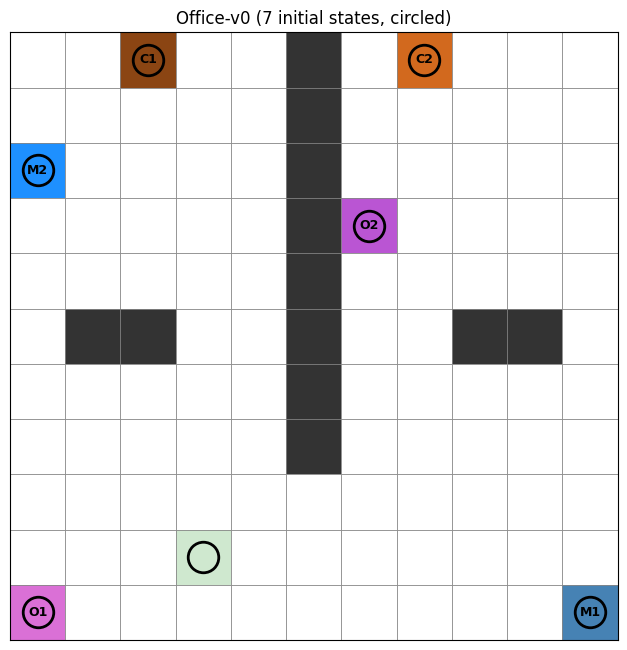

In [113]:
MAP = office_env.core.MAP
height, width = MAP.shape

color_map = {"X": "#333333", "_": "#cfe8cf", " ": "#ffffff"}
object_colors = {
    "C1": "#8B4513", "C2": "#D2691E",
    "M1": "#4682B4", "M2": "#1E90FF",
    "O1": "#DA70D6", "O2": "#BA55D3",
}
color_map.update(object_colors)


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            sym = MAP[r, c]
            color = color_map.get(sym, "#ffffff")
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if sym not in ("X", " ", "_"):
                ax.text(*cell_center(r, c), sym, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
for s in office_env.core.initial:
    x, y = cell_center(*s)
    ax.plot(x, y, marker="o", markersize=22, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=5)
ax.set_title(f"Office-v0 ({len(office_env.core.initial)} initial states, circled)")
plt.tight_layout()
plt.show()

## 4. MDP basics: state, action, reward, initial state

Office is a standard MDP $(S, A, P, R, \gamma)$ -- worth pinning each piece down concretely
before treating the env as a black box:

- **State** $S$: a grid cell `(row, col)`, held internally as `office_env.core.state`. Our
  adapter's `reset`/`step` return it *normalized* into `[0, 1]` (Section 1) since that's
  what `observation_space` declares -- but the environment's own logic (walls, objects,
  transitions) all operates on the raw `(row, col)` pair.
- **Action** $A$: 4 discrete moves, defined as class constants on `GridEnv`
  (`grid_envs.py:11`): `LEFT=0, UP=1, RIGHT=2, DOWN=3`.
- **Transition** $P(s'\mid s,a)$: deterministic here (`random_act_prob=0.0`) -- move one
  cell in the chosen direction. Two special cases, both handled by `base_movement`
  (`grid_envs.py:125-142`): walking into a wall (`'X'`) or off the grid edge **doesn't
  raise an error, it self-loops** (you stay put); walking onto an object cell moves you
  there and ends the episode.
- **Reward** $R$: the vector `phi` returned by `step()` -- all zeros *except* on the step
  that lands on an object cell, where it's a one-hot indicator of which one
  (`features`, `grid_envs.py:184-192`). `is_done` (`grid_envs.py:181-182`) fires on that
  exact same condition, so reward and termination always coincide here.
- **Initial state**: `reset()` with no arguments samples uniformly from
  `office_env.core.initial` -- 7 states with `ADD_OBJ_TO_START=True` (the `_` tile plus
  all 6 object cells). Our adapter's `reset(options={"state": (row, col)})` forces a
  *specific* start instead (useful for controlled demos, like the ones below).

The cell below exercises all four pieces directly, using the actual outcomes (verified by
running them, not predicted): a plain move, a wall bump (self-loop), and a move that lands
on an object (reward + termination).

In [115]:
ACTIONS = {
    office_env.core.LEFT: "LEFT",
    office_env.core.UP: "UP",
    office_env.core.RIGHT: "RIGHT",
    office_env.core.DOWN: "DOWN",
}
print("Action space:", ACTIONS)

print("\nInitial-state distribution (uniform over these, one drawn per reset()):")
for s in office_env.core.initial:
    print(f"  {s}  ({MAP[s]!r})")


def demo_step(start_state, action):
    obs, info = office_env.reset(options={"state": start_state})
    obs, reward, terminated, truncated, info = office_env.step(action)
    print(f"\nstart={start_state}  action={ACTIONS[action]}"
          f"\n  -> new state={tuple(office_env.core.state)}  reward(phi)={reward}"
          f"\n  -> terminated={terminated}  proposition={info['proposition']!r}")


# 1. A plain move: nothing special, just S -> S' under P
demo_step(start_state=(9, 3), action=office_env.core.UP)

# 2. A wall bump: (0,4) --RIGHT--> (0,5) is 'X', so P self-loops back to (0,4)
demo_step(start_state=(0, 4), action=office_env.core.RIGHT)

# 3. Landing on an object: (0,1) --RIGHT--> (0,2) is 'C1' -> reward fires, episode ends
demo_step(start_state=(0, 1), action=office_env.core.RIGHT)

Action space: {0: 'LEFT', 1: 'UP', 2: 'RIGHT', 3: 'DOWN'}

Initial-state distribution (uniform over these, one drawn per reset()):
  (2, 0)  ('M2')
  (10, 0)  ('O1')
  (0, 2)  ('C1')
  (9, 3)  ('_')
  (3, 6)  ('O2')
  (0, 7)  ('C2')
  (10, 10)  ('M1')

start=(9, 3)  action=UP
  -> new state=(8, 3)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 4)  action=RIGHT
  -> new state=(0, 4)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 1)  action=RIGHT
  -> new state=(0, 2)  reward(phi)=[1. 0. 0. 0. 0. 0.]
  -> terminated=True  proposition='C1'


<h3> Implementing OKB 

### Algorithm 1 (OKB), lines 1-4: seeding the behavior basis

The paper's pseudocode (`OKB/NeurIPS-2025-...pdf`, Alg. 1, p.5):

```
Input: MPC with features φ(s,a) ∈ R^d
1  π_w, ψ^π_w  ←  NewPolicy(w = InitialTask())
2  Π_0 ← {π_w};  Ψ_0^base ← {ψ^π_w}
3  Ψ_0^OK ← {};  W_0^sup ← {}
4  Initialize meta-policy ω_0
```

`NewPolicy(w)` is a black-box oracle in the pseudocode. `okb.py`'s own implementation
realizes it with a deep, JAX-based universal successor-feature network -- reasonable for
the paper's benchmarks (Minecart, HighWay, pixel-based Item Collector), but overkill for
Office: an 11x11 grid, 4 actions, 6 features. `π_w` and `ψ^π_w` can instead be learned with
the *same* tabular optimistic Q-learning recipe already validated end-to-end on Deep Sea
Treasure (`SFOLS/02_sfols_implementation.ipynb`, Section 2): `SFTable`
(state -> (num_actions, feat_dim) array), `gpi_action` (argmax with random tie-breaking),
and `solve_task` (fresh from-scratch optimistic TD-learning per weight).

**One real difference from DST, found by running it, not assumed.** DST's optimistic
default `(25, 0)` worked because its 2 features are independent (treasure can be large,
time is always <=0, so summing the two per-feature bounds never overshoots by much).
Office's 6 features are *mutually exclusive* -- `is_done` (`grid_envs.py:181-182`) ends
the episode the instant any object is touched, so at most one of the six is ever nonzero,
ever. Reusing DST's style of default, `[1,1,1,1,1,1]`, is *technically* still a valid upper
bound for any simplex weight (`default @ w = sum(w) = 1`), but it's a catastrophically
loose one: it pretends all 6 rewards are simultaneously collectible, so it overshoots the
true max achievable value (at best `max_i w_i`, since only one feature is ever attainable)
by up to 6x for weights like the uniform `InitialTask()`. Checked directly: with the flat
default, the greedy policy actively *avoids* terminating (only 1,219 terminations in
100k steps -- wandering into never-yet-updated, still-falsely-amazing-looking territory
looks greedily better than a small but real terminal reward), and `psi^pi_w` stays
suspiciously identical across all 6 features even after 100k steps, just slowly decaying
instead of ever differentiating.

**Fix**: make the optimistic default *weight-dependent* -- a one-hot vector on whichever
feature `w` weights most, `argmax(w)`. This is the natural generalization of DST's trick to
a mutually-exclusive reward structure: `default @ w = max_i w_i`, a *tight* upper bound on
the true achievable value regardless of whether `w` is one-hot or uniform. Checked directly:
terminations jumped to 9,051 in just 20k steps (vs. 1,219 in 100k), and `psi^pi_w` for the
uniform task converged to a sensible, differentiated vector (scalarized value `~0.166`,
matching the true max `1/6` almost exactly) instead of a flat, still-decaying one.

In [116]:
import random


class SFTable:
    """Tabular successor-feature table: state -> (num_actions, feat_dim) array.
    Identical to SFOLS/02_sfols_implementation.ipynb's version."""

    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec  # (num_actions, feat_dim), used for any never-visited state
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def gpi_action(rng, state, w, sf_tables):
    """argmax_a max_i psi_i(state, a) . w, breaking ties uniformly at random (matters a
    lot with optimistic initialization -- see the DST notebook's Section 1)."""
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)
    action_values = values.max(axis=0)
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


NUM_STEPS_PER_POLICY = 50_000  # tabular Q-learning is cheap here: ~10s for this many steps

In [117]:
def solve_task(env, w, num_steps=NUM_STEPS_PER_POLICY, alpha=0.1, gamma=GAMMA,
               eps_start=1.0, eps_end=0.05, seed=0):
    """Learn a tabular SF psi(s,a) for a single scalarized task r.w, via optimistic
    tabular TD-learning -- same recipe as SFOLS/02_sfols_implementation.ipynb's
    solve_task, except the optimistic default is a one-hot vector on argmax(w) instead
    of a fixed constant (see the markdown above for why that matters here)."""
    rng = random.Random(seed)
    n_actions = env.action_space.n
    feat_dim = env.reward_dim

    optimistic_vec = np.zeros(feat_dim, dtype=np.float32)
    optimistic_vec[np.argmax(w)] = 1.0
    default_vec = np.tile(optimistic_vec, (n_actions, 1))
    psi = SFTable(n_actions, feat_dim, default_vec)

    obs, _ = env.reset()
    state = tuple(env.core.state)
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / (0.5 * num_steps))
        if rng.random() < eps:
            action = rng.randrange(n_actions)
        else:
            action = gpi_action(rng, state, w, [psi])

        _, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)

        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(env.core.state)
        else:
            state = next_state
    return psi


def expected_sf(psi_table, w, initial_states):
    """psi^pi (Eq. 2, expectation over the initial-state distribution mu). Office has 7
    equally-likely start states (Section 4 above), not DST's single START_STATE, so
    average the greedy SF over all of them -- an exact expectation, no rollout noise,
    matching office_ccs_results.ipynb's policy_eval_exact (Section 2.5 there)."""
    vecs = [psi_table[tuple(s0)][np.argmax(psi_table[tuple(s0)] @ w)] for s0 in initial_states]
    return np.mean(vecs, axis=0)


def new_policy(env, w, num_steps=NUM_STEPS_PER_POLICY, seed=0):
    """NewPolicy(w) (Algorithm 1, line 1 -- also reused at line 14 later on): train psi(s,a)
    from scratch for weight w, then return (pi_w, psi^pi_w). pi_w is the trained SFTable
    itself here (unlike the neural version, each weight really does get its own table)."""
    psi_table = solve_task(env, w, num_steps=num_steps, seed=seed)
    psi_w = expected_sf(psi_table, w, env.core.initial)
    return psi_table, psi_w

initial task w = [0 1 0 0 0 0]
psi^pi_w        = [0.    0.905 0.    0.    0.    0.   ]   (per-feature expected discounted return)
scalarized value = 0.905   (true max for uniform w is 1/d = 0.167)
|Pi_0|=1  |Psi_0^base|=1  |Psi_0^OK|=0  |W_0^sup|=0


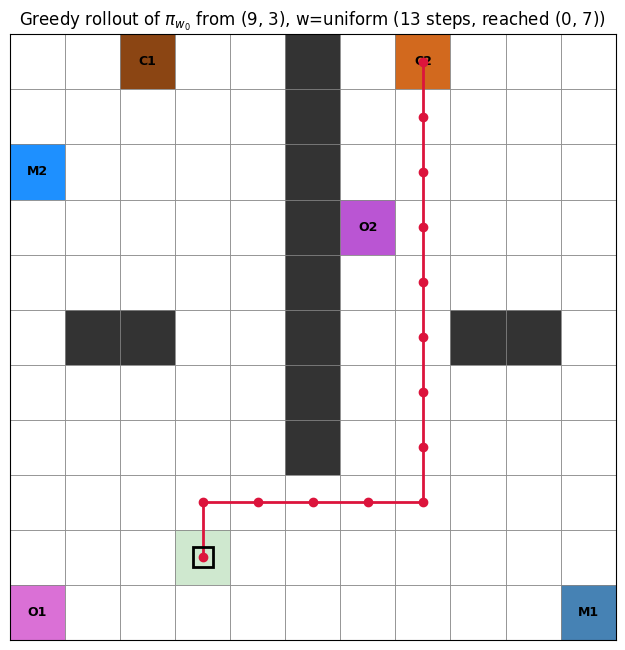

In [118]:
# --- Algorithm 1, lines 1-4 ---
d = office_env.reward_dim
initial_task = np.array([0,1,0,0,0,0])#np.ones(d, dtype=np.float32) / d          # w = InitialTask() = [1/d, ..., 1/d], as in the paper

pi_w0, psi0 = new_policy(office_env, initial_task, num_steps=NUM_STEPS_PER_POLICY, seed=SEED)  # line 1

Pi_base = [pi_w0]         # Pi_0 <- {pi_w}         (line 2)
Psi_base = [psi0]         # Psi_0^base <- {psi^pi_w}
W_exp = [initial_task]     # which weight trained each entry of Pi_base/Psi_base (bookkeeping, mirrors DST notebook)
Psi_OK = []                # Psi_0^OK <- {}         (line 3)
W_sup = []                 # W_0^sup <- {}
omega = None                # meta-policy omega_0 -- not trained until OK-LS, line 6+ (line 4)

print(f"initial task w = {initial_task.round(3)}")
print(f"psi^pi_w        = {psi0.round(3)}   (per-feature expected discounted return)")
print(f"scalarized value = {np.dot(psi0, initial_task):.3f}   (true max for uniform w is 1/d = {1/d:.3f})")
print(f"|Pi_0|={len(Pi_base)}  |Psi_0^base|={len(Psi_base)}  |Psi_0^OK|={len(Psi_OK)}  |W_0^sup|={len(W_sup)}")


def rollout_trajectory(env, psi_table, w, start_state, max_steps=200, seed=0):
    """Greedy (no-exploration) rollout of the tabular policy pi_w = argmax_a psi(s,a).w,
    from a fixed start state -- for visualizing what NewPolicy(w) actually learned."""
    rng = random.Random(seed)
    env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    trajectory = [state]
    reached_object = False
    for _ in range(max_steps):
        action = gpi_action(rng, state, w, [psi_table])
        _, _, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        trajectory.append(state)
        if terminated:
            reached_object = True
        if terminated or truncated:
            break
    return trajectory, reached_object


traj_start = (9, 3)  # the '_' tile -- the one initial state that isn't already sitting on an object
trajectory, reached_object = rollout_trajectory(office_env, pi_w0, initial_task, traj_start)

fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
xs, ys = zip(*[cell_center(*s) for s in trajectory])
ax.plot(xs, ys, "-o", color="crimson", markersize=6, linewidth=2, zorder=6)
ax.plot(xs[0], ys[0], marker="s", markersize=14, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=7)
outcome = f"reached {trajectory[-1]}" if reached_object else "timed out"
ax.set_title(f"Greedy rollout of $\\pi_{{w_0}}$ from {traj_start}, w=uniform ({len(trajectory) - 1} steps, {outcome})")
plt.tight_layout()
plt.show()

### Algorithm 3 (TrainOK): training the meta-policy $\omega$

`NewPolicy(w)` only ever has to answer for *one fixed* `w`, so a lookup table was enough.
The meta-policy $\omega: S\times\mathcal{W}\to\mathcal{Z}$ and its critic $\psi^\omega(s,z,w)$
are different in kind: $\mathcal{Z}$ (unit vectors in $\mathbb{R}^d$, paper footnote 1, p.3)
and $\mathcal{W}$ (the simplex) are both continuous, so there is no table to fill in --
this is a genuine function-approximation problem, hence PyTorch.

The paper's pseudocode (`OKB/NeurIPS-2025-...pdf`, Alg. 3, App. D, p.19):

```
Algorithm 3: Train Option Keyboard (TrainOK)
Input: Meta-policy ω, weight support W^sup, base policies Π.
1  Initialize replay buffer B
2  Let ψ^ω(s, z, w) be the critic of the meta-policy ω
3  w_0 ~ W^sup;  S_0 ~ μ
4  for t = 0, 1, 2, ..., T do
5    if S_t is terminal then
6        w_t ~ W^sup
7        S_t ~ μ
8    z_t ← ω(S_t, w)
       ▷ Exploration: clipped Gaussian noise, as in TD3
9    z_t ← z_t + clip(ε, -0.5, 0.5), where ε ~ N(0, 0.2²)
10   z_t ← z_t / ||z_t||_2
       ▷ Follow OK policy
11   A_t ← π^GPI(S_t, z_t; Π)
12   Execute A_t, observe S_{t+1}, and φ_t
13   Add (S_t, z_t, φ_t, S_{t+1}) to B
14   Update ψ^ω by minimizing
        E_{(s,z,φ,s')~B, w~W^sup} [(ψ^ω(s,z,w) - (φ + γ ψ^ω(s', ω(s',w), w)))²]
15   Update ω via the policy gradient ∇_z ψ^ω(s,z,w)·w |_{z=ω(s,w)} ∇_ω ω(s,w)
16  return ω
```

Mapping this onto code, cell by cell below:

- **Lines 1-2** (`ReplayBuffer`, `MetaCritic`): a plain circular buffer over
  $(s,z,\phi,s')$, and a small MLP critic. Note the buffer does **not** store $w_t$ --
  line 14 resamples $w\sim\mathcal{W}^{\text{sup}}$ independently for every minibatch.
  This is valid for the same reason ordinary off-policy Q-learning is valid: the executed
  action $A_t=\pi^{\text{GPI}}(S_t,z_t;\Pi)$ is already fully determined by $(S_t,z_t)$
  once it happened, so $(s,z,\phi,s')$ is a self-contained transition regardless of which
  $w$ the agent happened to be "trying to solve" when it was collected -- $w$ only enters
  through which continuation $\omega(s',w)$ is used to bootstrap the target.
- **Lines 3, 5-7**: episode-boundary bookkeeping, identical in spirit to `solve_task`'s
  reset logic, just resampling a task from $\mathcal{W}^{\text{sup}}$ too.
- **Lines 8-10**: the actor's forward pass plus TD3-style clipped Gaussian exploration,
  renormalized back onto the unit sphere $\mathcal{Z}$ (`MetaPolicy.forward` already
  normalizes its raw output, so lines 9-10 are two separate normalizations -- once inside
  the network, once after adding noise).
- **Line 11**: reuses the *exact same* `gpi_action` helper written for the tabular
  `solve_task` -- $\pi^{\text{GPI}}(s,z;\Pi)$ is not a new operation, it is literally
  `gpi_action(rng, state, z, Pi_base)`, since GPI (Eq. 3) is defined for *any* vector fed
  into the dot product with the SFs, not just a task weight.
- **Line 14, deviation #1 (target networks), found by running it, not assumed.** The
  literal reading of line 14 bootstraps off the *live* $(\omega,\psi^\omega)$ -- and doing
  that here made the critic loss diverge (observed directly: climbing past $10^{13}$,
  worse with more steps). Mechanism: the actor (line 15) is trained to move $z$ toward
  wherever the critic currently scores highest; if the critic slightly overestimates
  there (inevitable at init), the actor chases that peak; the *next* critic update then
  bootstraps its target off $\psi^\omega(s',\omega(s',w),w)$, which the actor was just
  pushed toward, so the target grows; regressing onto it pushes the critic up further;
  repeat, amplified by $\gamma=0.99$. This is exactly why DQN/DDPG/TD3 use **target
  networks**: a slowly Polyak-averaged copy $(\omega_{\text{target}},\psi_{\text{target}})$
  supplies the bootstrap target instead. App. F notes the paper removes target networks,
  but only as part of a package deal with Bhatt et al. (2024)'s batch-norm/layer-norm
  stabilization as a *replacement* -- since that substitute isn't implemented here,
  target networks are reinstated below to get the standard stabilization instead.
- **Line 14/15, deviation #2 (target policy smoothing + delayed policy updates), also
  found by running it.** Target networks alone fixed the *divergence*, but not a second,
  subtler failure: the OK-policy would settle into an infinite loop between two adjacent
  cells instead of reaching the goal. Diagnosed directly (see the state-by-state dump
  further below): at the looping states, $z$'s sign on the one feature dimension that
  actually matters here would occasionally flip, which -- since GPI's argmax is a
  discontinuous function of $z$ -- reverses the chosen action entirely. Ran for 150k
  steps to rule out "just needs more training": the flip persisted, so this is a
  structural actor-critic instability, not undertraining -- the actor is doing exactly
  what DDPG is known to do without further safeguards: exploiting narrow, not-yet-converged
  spikes in the critic (worse here because GPI's argmax makes the true $z\mapsto$ return
  mapping discontinuous, so a smooth MLP critic *cannot* fit it perfectly, leaving
  permanent small spikes to exploit). Fixed with TD3's other two standard tricks: (i)
  *target policy smoothing* -- perturb $z_{\text{next}}$ with clipped noise before it
  enters the bootstrap target, so the critic is regressed toward a neighborhood average
  rather than one exact (possibly-spiky) point; (ii) *delayed policy updates* -- update
  the actor (and Polyak-average the targets) only every `policy_delay` critic steps, so
  the critic partially settles before the actor exploits its current shape. Checked
  directly: with both in place, the OK-policy's greedy rollout exactly reproduces the
  tabular $\pi_{w_0}$'s path again, this time robustly.
- **Line 15**: exactly DDPG/TD3's deterministic policy gradient, with the critic's
  vector output scalarized via $\cdot\,w$ before differentiating -- maximize
  $\psi^\omega(s,\omega(s,w),w)\cdot w$ w.r.t. $\omega$'s parameters only (critic frozen),
  using the *live* critic (only the bootstrap target needed decoupling via target nets,
  not the actor's own objective).

Algorithm 2 (OK-LS) is the outer loop that calls this repeatedly, growing
$\mathcal{W}^{\text{sup}}$ via `CornerW`/`RemoveDominated` between calls -- that's the next
step once `TrainOK` itself is validated below.

In [119]:
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F


class MetaPolicy(nn.Module):
    """omega(s, w) -> z in Z (unit vectors in R^d), Alg. 3 line 8. State input is the same
    normalized (row, col) in [0,1]^2 that office_env already exposes as its observation
    (Section 1) -- no extra state embedding needed for a domain this low-dimensional."""

    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + task_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, task_dim),
        )

    def forward(self, s, w):
        z = self.net(torch.cat([s, w], dim=-1))
        return F.normalize(z, dim=-1, eps=1e-8)


class MetaCritic(nn.Module):
    """psi^omega(s, z, w) -> SF vector in R^d, Alg. 3 line 2: the critic of the meta-policy,
    predicting the discounted feature return of taking z at s then following pi^OK_omega(.,w)."""

    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + 2 * task_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, task_dim),
        )

    def forward(self, s, z, w):
        return self.net(torch.cat([s, z, w], dim=-1))


class ReplayBuffer:
    """Alg. 3 line 1 (B). Stores (s, z, phi, s') -- deliberately NOT w, since the critic
    update (line 14) resamples w ~ W^sup fresh for every minibatch (see train_ok below)."""

    def __init__(self, capacity, state_dim, task_dim):
        self.capacity = capacity
        self.s = np.zeros((capacity, state_dim), dtype=np.float32)
        self.z = np.zeros((capacity, task_dim), dtype=np.float32)
        self.phi = np.zeros((capacity, task_dim), dtype=np.float32)
        self.s_next = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros((capacity,), dtype=np.float32)
        self.ptr = 0
        self.size = 0

    def add(self, s, z, phi, s_next, done):
        i = self.ptr
        self.s[i], self.z[i], self.phi[i] = s, z, phi
        self.s_next[i], self.done[i] = s_next, float(done)
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.size, size=batch_size)
        return self.s[idx], self.z[idx], self.phi[idx], self.s_next[idx], self.done[idx]

In [120]:
def train_ok(env, omega, psi_omega, W_sup, Pi_base, num_steps=20_000, batch_size=128,
             gamma=GAMMA, actor_lr=3e-4, critic_lr=1e-3, buffer_capacity=20_000,
             noise_std=0.2, tau=0.005, policy_delay=2, target_noise_std=0.2, seed=0):
    """Algorithm 3 (TrainOK). Trains (omega, psi_omega) in place and returns them, plus a
    log of critic losses (one every 100 steps) for a quick convergence check.

    Two deviations from the pseudocode, both found necessary by running it (see the
    markdown above), both standard TD3 (Fujimoto et al. 2018) stabilizers -- the same
    paper OKB already cites for the exploration-noise scheme (line 9):
      1. Target networks (omega_target, psi_target), Polyak-averaged with rate tau, supply
         the bootstrap target instead of the live nets -- without this the critic diverges.
      2. Target policy smoothing + delayed policy updates (policy_delay) -- without these,
         the critic converges (bounded loss) but the actor still gets stuck exploiting
         narrow, noisy spikes in an imperfectly-fit critic: checked directly, with
         policy_delay=1 and no target smoothing the OK-policy oscillated forever between
         two adjacent cells (confirmed NOT an undertraining artifact -- persisted at
         150k steps), even though the critic loss itself looked fine."""
    rng = np.random.default_rng(seed)     # numpy rng: exploration noise, minibatch sampling
    py_rng = random.Random(seed)          # python rng: gpi_action's tie-breaking (see Section on gpi_action)

    task_dim = env.reward_dim
    state_dim = 2
    buffer = ReplayBuffer(buffer_capacity, state_dim, task_dim)
    W_sup_arr = np.stack(W_sup).astype(np.float32)

    omega_target = copy.deepcopy(omega)
    psi_target = copy.deepcopy(psi_omega)
    for p in omega_target.parameters():
        p.requires_grad_(False)
    for p in psi_target.parameters():
        p.requires_grad_(False)

    actor_opt = torch.optim.Adam(omega.parameters(), lr=actor_lr)
    critic_opt = torch.optim.Adam(psi_omega.parameters(), lr=critic_lr)

    def sample_tasks(n):
        return W_sup_arr[rng.integers(len(W_sup_arr), size=n)]

    # --- line 3: w_0 ~ W^sup; S_0 ~ mu ---
    w_t = sample_tasks(1)[0]
    obs, _ = env.reset()
    state = tuple(env.core.state)

    critic_losses = []
    for t in range(num_steps):
        # --- lines 5-7: resample task + state on episode boundaries ---
        if t > 0 and (terminated or truncated):
            w_t = sample_tasks(1)[0]
            obs, _ = env.reset()
            state = tuple(env.core.state)

        # --- lines 8-10: z_t = omega(S_t, w_t) + clipped Gaussian noise, renormalized to Z ---
        with torch.no_grad():
            s_in = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
            w_in = torch.as_tensor(w_t, dtype=torch.float32).unsqueeze(0)
            z_t = omega(s_in, w_in).squeeze(0).numpy()
        noise = np.clip(rng.normal(0.0, noise_std, size=task_dim), -0.5, 0.5)
        z_t = z_t + noise
        z_t = z_t / (np.linalg.norm(z_t) + 1e-8)

        # --- line 11: A_t = pi^GPI(S_t, z_t; Pi) -- exactly our tabular gpi_action, with
        # z_t standing in for the "weight" argument (Eq. 3: GPI is defined for ANY vector,
        # not just a task weight -- z is just the vector the meta-policy hands to GPI) ---
        action = gpi_action(py_rng, state, z_t, Pi_base)

        # --- lines 12-13: step env, store transition (note: w_t is NOT stored -- see below) ---
        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)
        buffer.add(obs, z_t, phi, next_obs, terminated)

        obs, state = next_obs, next_state

        # --- line 14: critic update. w is resampled fresh from W^sup independent of which
        # w_t generated the transition -- valid because (s, z_t, phi, s') alone fixes what
        # actually happened (a = pi^GPI(s, z_t; Pi) is deterministic given z_t), so this is
        # plain off-policy TD learning, just relabeled with a different task for the
        # bootstrap target each time (a universal-SF analogue of what solve_task's tabular
        # Q-learning does for a single fixed w). Bootstrap target uses the SLOWLY-MOVING
        # target networks (omega_target, psi_target), not the live ones -- see markdown. ---
        if buffer.size >= batch_size:
            s_b, z_b, phi_b, s_next_b, done_b = buffer.sample(batch_size, rng)
            w_b = torch.as_tensor(sample_tasks(batch_size), dtype=torch.float32)
            s_b = torch.as_tensor(s_b)
            z_b = torch.as_tensor(z_b)
            phi_b = torch.as_tensor(phi_b)
            s_next_b = torch.as_tensor(s_next_b)
            done_b = torch.as_tensor(done_b).unsqueeze(-1)

            with torch.no_grad():
                z_next = omega_target(s_next_b, w_b)
                # TD3 target policy smoothing: perturb the target action before evaluating
                # it, so the critic can't be regressed onto (and later exploited via) a
                # narrow, unconverged spike at one exact z -- it has to be robust to a
                # neighborhood around it.
                smoothing_noise = torch.clamp(
                    torch.randn_like(z_next) * target_noise_std, -0.5, 0.5)
                z_next = F.normalize(z_next + smoothing_noise, dim=-1, eps=1e-8)
                psi_next = psi_target(s_next_b, z_next, w_b)
                target = phi_b + gamma * (1.0 - done_b) * psi_next

            pred = psi_omega(s_b, z_b, w_b)
            critic_loss = F.mse_loss(pred, target)
            critic_opt.zero_grad()
            critic_loss.backward()
            critic_opt.step()

            if t % 100 == 0:
                critic_losses.append(critic_loss.item())

            # --- TD3 delayed policy updates: only push the actor (and Polyak-average the
            # targets) every policy_delay critic steps, so the critic gets a chance to
            # settle before the actor exploits its current shape. Without this, actor and
            # critic chase each other's noise every single step (observed directly: with
            # policy_delay=1, the OK-policy oscillates between two adjacent cells forever
            # instead of converging, even after 150k steps). ---
            if t % policy_delay == 0:
                # line 15: maximize the *scalarized* critic psi_omega(s,omega(s,w),w).w
                # w.r.t. omega's params only (critic frozen -- only actor_opt steps).
                z_pi = omega(s_b, w_b)
                q_scalar = (psi_omega(s_b, z_pi, w_b) * w_b).sum(dim=-1)
                actor_loss = -q_scalar.mean()
                actor_opt.zero_grad()
                actor_loss.backward()
                actor_opt.step()

                with torch.no_grad():
                    for p, tp in zip(omega.parameters(), omega_target.parameters()):
                        tp.data.mul_(1.0 - tau).add_(tau * p.data)
                    for p, tp in zip(psi_omega.parameters(), psi_target.parameters()):
                        tp.data.mul_(1.0 - tau).add_(tau * p.data)

    return omega, psi_omega, critic_losses

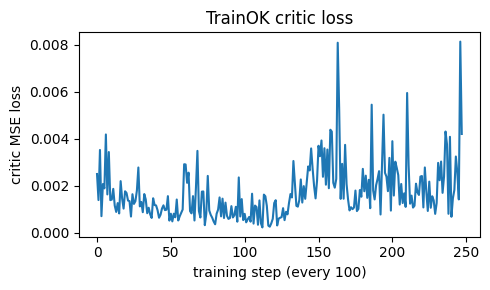

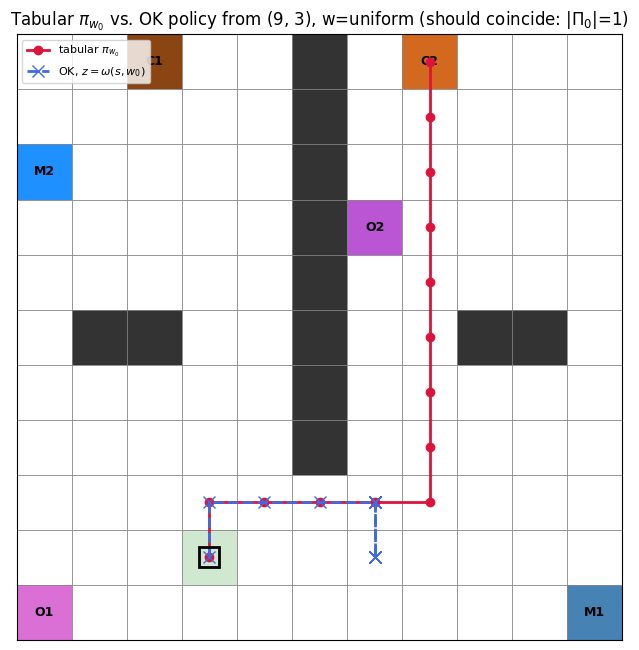

tabular trajectory:  [(9, 3), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (7, 7), (6, 7), (5, 7), (4, 7), (3, 7), (2, 7), (1, 7), (0, 7)]
OK-policy trajectory: [(9, 3), (8, 3), (8, 4), (8, 5), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9, 6), (8, 6), (9,

In [122]:
# --- Smoke-test TrainOK with the only ingredients we currently have ---
# Algorithm 2 (OK-LS) is the outer loop that repeatedly calls TrainOK, growing W^sup via
# CornerW(Psi^OK) between calls -- that scaffolding (CornerW, RemoveDominated, the
# Psi^OK bookkeeping) is the next step. For now, validate TrainOK in isolation using
# exactly what Algorithm 1 has handed us so far: Pi_base = [pi_w0], W_sup = [initial_task].
#
# With a single base policy, pi^GPI(s, z; Pi_base) = pi_w0 for *any* z (GPI/argmax over a
# 1-element set ignores z entirely) -- so the OK policy should collapse to exactly the
# tabular policy already trained in the previous cell, regardless of what omega learns.
# That's a strong, checkable sanity condition before trusting TrainOK on a real Pi_base.

torch.manual_seed(SEED)
state_dim = 2
omega = MetaPolicy(state_dim, d)
psi_omega = MetaCritic(state_dim, d)

W_sup = [initial_task]

omega, psi_omega, critic_losses = train_ok(
    office_env, omega, psi_omega, W_sup, Pi_base,
    num_steps=25_000, batch_size=128, seed=SEED,
)

plt.figure(figsize=(5, 3))
plt.plot(critic_losses)
plt.xlabel("training step (every 100)")
plt.ylabel("critic MSE loss")
plt.title("TrainOK critic loss")
plt.tight_layout()
plt.show()


# Evaluate: does the OK policy (with z = omega(s, w), no exploration noise) reproduce the
# same rollout as the plain tabular pi_w0 from the same start state and weight?
def ok_policy_action(rng, state_raw, obs_norm, w, omega, sf_tables):
    with torch.no_grad():
        s_t = torch.as_tensor(obs_norm, dtype=torch.float32).unsqueeze(0)
        w_t = torch.as_tensor(w, dtype=torch.float32).unsqueeze(0)
        z = omega(s_t, w_t).squeeze(0).numpy()
    return gpi_action(rng, state_raw, z, sf_tables)


def rollout_ok_trajectory(env, omega, w, sf_tables, start_state, max_steps=200, seed=0):
    rng = random.Random(seed)
    obs, _ = env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    trajectory = [state]
    reached_object = False
    for _ in range(max_steps):
        action = ok_policy_action(rng, state, obs, w, omega, sf_tables)
        obs, _, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        trajectory.append(state)
        if terminated:
            reached_object = True
        if terminated or truncated:
            break
    return trajectory, reached_object


trajectory_ok, reached_ok = rollout_ok_trajectory(office_env, omega, initial_task, Pi_base, traj_start)

fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
xs, ys = zip(*[cell_center(*s) for s in trajectory])
xs_ok, ys_ok = zip(*[cell_center(*s) for s in trajectory_ok])
ax.plot(xs, ys, "-o", color="crimson", markersize=6, linewidth=2, zorder=6, label="tabular $\\pi_{w_0}$")
ax.plot(xs_ok, ys_ok, "--x", color="royalblue", markersize=8, linewidth=2, zorder=7, label="OK, $z=\\omega(s,w_0)$")
ax.plot(xs[0], ys[0], marker="s", markersize=14, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=8)
ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"Tabular $\\pi_{{w_0}}$ vs. OK policy from {traj_start}, w=uniform (should coincide: |$\\Pi_0$|=1)")
plt.tight_layout()
plt.show()

print(f"tabular trajectory:  {trajectory}")
print(f"OK-policy trajectory: {trajectory_ok}")
print(f"identical: {trajectory == trajectory_ok}")

## 5. The ground-truth CCS (SFOLS + GPI), and then OKB with fewer base policies

I want you to compute the successor features for the six corner weights here:

Before anything else: compute the *actual* ground-truth CCS via the same SFOLS
algorithm `office_ccs_results.ipynb` uses (OLS's corner-weight priority queue, driven by
GPI-based improvement estimates instead of the LP bound, which doesn't scale well past a
few objectives) -- just adapted to reuse *this* notebook's own tabular `new_policy` /
`SFTable` machinery instead of `sf-fsa-vi`'s neural `SF`/`GPI` classes, for the same reason
Section "Algorithm 1, lines 1-4" above skipped OKB's own deep `NewPolicy`: overkill for an
11x11 grid. `TabularGPIAgent` is the adapter that lets `OLS.next_w`'s GPI-based priority
path call into our tabular policies.

In [132]:
class TabularGPIAgent:
    """Minimal adapter satisfying rl.utils.eval.eval_mo's `agent.eval(obs, w)` + `agent.gamma`
    interface, so OLS.next_w's GPI-based priority path (SFOLS) can be reused directly with
    our tabular Pi_CCS-so-far, instead of the LP-bound path that doesn't scale well."""

    def __init__(self, env, sf_tables, gamma, seed=0):
        self.env = env
        self.sf_tables = sf_tables
        self.gamma = gamma
        self.rng = random.Random(seed)

    def eval(self, obs, w):
        state = tuple(self.env.core.state)
        return gpi_action(self.rng, state, w, self.sf_tables)


MAX_CCS_ITERATIONS = 23
CCS_EPSILON = 0.01

ols = OLS(m=d, epsilon=CCS_EPSILON)
policies_by_weight = {}   # rounded-weight tuple -> (pi_table, psi_vector), avoids retraining
                          # a policy if the exact same weight is ever revisited
gpi_agent = TabularGPIAgent(office_env, [], GAMMA, seed=SEED)

iteration = 0
w = ols.next_w()   # first d calls: ccs is empty, so this just pops the pre-seeded extrema queue
while w is not None and iteration < MAX_CCS_ITERATIONS:
    iteration += 1
    key = tuple(np.round(w, 6))
    if key not in policies_by_weight:
        pi_table, psi_w = new_policy(office_env, w, num_steps=NUM_STEPS_PER_POLICY, seed=SEED)
        policies_by_weight[key] = (pi_table, psi_w)
    else:
        pi_table, psi_w = policies_by_weight[key]
    ols.add_solution(psi_w, w)
    gpi_agent.sf_tables = [policies_by_weight[tuple(np.round(cw, 6))][0] for cw in ols.ccs_weights]
    w = ols.next_w(gpi_agent=gpi_agent, env=office_env, rep_eval=len(office_env.core.initial))

CCS = ols.ccs
CCS_weights = ols.ccs_weights
Pi_CCS = [policies_by_weight[tuple(np.round(w, 6))][0] for w in CCS_weights]

print(f"\n=== CCS computation finished: {iteration} policies trained, |CCS| = {len(CCS)} ===")
for w, psi in zip(CCS_weights, CCS):
    print(f"  w={np.round(w, 3)}  psi={np.round(psi, 3)}  value={np.dot(psi, w):.3f}")

ccs: []
ccs size: 0
Adding value [0.9102 0.     0.     0.     0.     0.    ] for weight [1. 0. 0. 0. 0. 0.]
CCS: [array([0.9102, 0.    , 0.    , 0.    , 0.    , 0.    ], dtype=float32)] CCS size: 1
Weight Support Set: [array([1., 0., 0., 0., 0., 0.])]
W_corner size: 6
queue: [(0.4602364642279489, array([0., 0., 1., 0., 0., 0.], dtype=float32)), (0.42857142857142855, array([0., 0., 0., 0., 0., 1.], dtype=float32)), (0.2857142857142857, array([0., 0., 0., 0., 1., 0.], dtype=float32)), (0.2842857156481062, array([0., 0., 0., 1., 0., 0.], dtype=float32)), (0.13449716567993164, array([0., 1., 0., 0., 0., 0.], dtype=float32))]
gap ols: 0.460236, ols w: [0. 0. 1. 0. 0. 0.]
ccs: [array([0.9102, 0.    , 0.    , 0.    , 0.    , 0.    ], dtype=float32)]
ccs size: 1
Adding value [0.     0.     0.9228 0.     0.     0.    ] for weight [0. 0. 1. 0. 0. 0.]
CCS: [array([0.9102, 0.    , 0.    , 0.    , 0.    , 0.    ], dtype=float32), array([0.    , 0.    , 0.9228, 0.    , 0.    , 0.    ], dtype=float32

In [133]:
# --- Successor features for the six corner weights of the reward simplex ---
# Office's 6 features are mutually exclusive (Section "Algorithm 1, lines 1-4" above: at
# most one object is ever touched per episode), so the simplex's corners are exactly the 6
# standard basis vectors e_1, ..., e_6 -- one pure objective per corner, same NewPolicy(w)
# oracle (SFTable + solve_task) used to seed Pi_base above. Named simplex_corner_weights
# (not corner_weights) to avoid shadowing the CornerW(Psi) function defined further below.
simplex_corner_weights = [np.eye(d)[i] for i in range(d)]

Pi_corners, Psi_corners = [], []
for i, w in enumerate(simplex_corner_weights):
    pi_w, psi_w = new_policy(office_env, w, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + i)
    Pi_corners.append(pi_w)
    Psi_corners.append(psi_w)
    print(f"corner {i} ({PHI_OBJ_TYPES[i]})  w={w}  psi={psi_w.round(3)}  value={np.dot(psi_w, w):.3f}")

corner 0 (C1)  w=[1. 0. 0. 0. 0. 0.]  psi=[0.911 0.    0.    0.    0.    0.   ]  value=0.911
corner 1 (C2)  w=[0. 1. 0. 0. 0. 0.]  psi=[0.    0.905 0.    0.    0.    0.   ]  value=0.905
corner 2 (O1)  w=[0. 0. 1. 0. 0. 0.]  psi=[0.    0.    0.923 0.    0.    0.   ]  value=0.923
corner 3 (O2)  w=[0. 0. 0. 1. 0. 0.]  psi=[0.    0.    0.    0.916 0.    0.   ]  value=0.916
corner 4 (M1)  w=[0. 0. 0. 0. 1. 0.]  psi=[0.    0.    0.    0.    0.911 0.   ]  value=0.911
corner 5 (M2)  w=[0. 0. 0. 0. 0. 1.]  psi=[0.    0.    0.    0.    0.    0.914]  value=0.914


,corner (pure objective),C1,C2,O1,O2,M1,M2
0,C1,0.910507,0.000000,0.000000,0.000000,0.000000,0.000000
1,C2,0.000000,0.904504,0.000000,0.000000,0.000000,0.000000
2,O1,0.000000,0.000000,0.922802,0.000000,0.000000,0.000000
3,O2,0.000000,0.000000,0.000000,0.915805,0.000000,0.000000
4,M1,0.000000,0.000000,0.000000,0.000000,0.911292,0.000000
5,M2,0.000000,0.000000,0.000000,0.000000,0.000000,0.913507


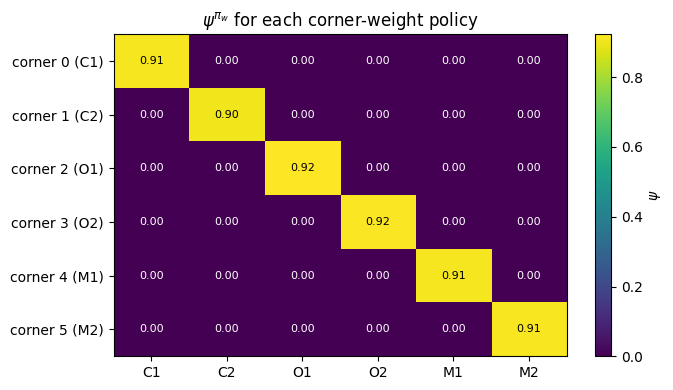

In [134]:
df_corners = pd.DataFrame(np.array(Psi_corners), columns=PHI_OBJ_TYPES)
df_corners.insert(0, "corner (pure objective)", PHI_OBJ_TYPES)
display(df_corners)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(np.array(Psi_corners), cmap="viridis", aspect="auto")
ax.set_xticks(range(d)); ax.set_xticklabels(PHI_OBJ_TYPES)
ax.set_yticks(range(d)); ax.set_yticklabels([f"corner {i} ({PHI_OBJ_TYPES[i]})" for i in range(d)])
for i in range(d):
    for j in range(d):
        val = Psi_corners[i][j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                 color="white" if val < np.array(Psi_corners).max() * 0.6 else "black", fontsize=8)
ax.set_title(r"$\psi^{\pi_w}$ for each corner-weight policy")
plt.colorbar(im, ax=ax, label=r"$\psi$")
plt.tight_layout()
plt.show()

### 5a. Training the meta-policy $\omega$ over the 6 corner-weight policies

**Hypothesis to test** (yours): Office's 6 features are mutually exclusive -- touching any
object ends the episode, so at most one feature is ever nonzero. Under that structure the
optimal policy for *any* weight `w` is simply "go to whichever object maximizes
`w_i * (discounted proximity)`", and each corner policy `Pi_corners[i]` already computes
the shortest path to object `i` from *every* state (it was trained on the pure objective
`e_i`, which only cares about reaching object `i`, not about `w`). So plain GPI over the 6
corners might already be exactly optimal for any `w`, with the meta-policy needed only to
pick a sensible `z` for GPI's argmax at interior weights.

We train `omega`/`psi_omega` exactly as in the smoke test above (Algorithm 3, TrainOK), but
now with the *real* base-policy set `Pi_corners` and the full weight support
`simplex_corner_weights` (all 6 corners), instead of the smoke test's trivial single-policy,
single-weight case.

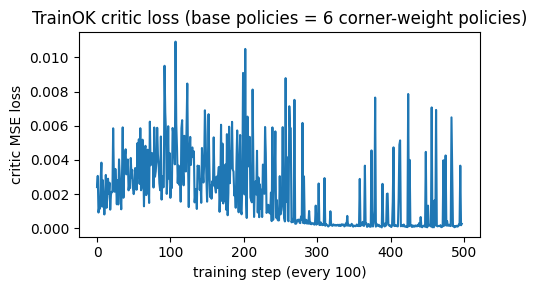

In [129]:
torch.manual_seed(SEED)
omega_corners = MetaPolicy(state_dim, d)
psi_omega_corners = MetaCritic(state_dim, d)

omega_corners, psi_omega_corners, critic_losses_corners = train_ok(
    office_env, omega_corners, psi_omega_corners, simplex_corner_weights, Pi_corners,
    num_steps=NUM_STEPS_PER_POLICY, batch_size=128, seed=SEED,
)

plt.figure(figsize=(5, 3))
plt.plot(critic_losses_corners)
plt.xlabel("training step (every 100)")
plt.ylabel("critic MSE loss")
plt.title("TrainOK critic loss (base policies = 6 corner-weight policies)")
plt.tight_layout()
plt.show()

### Does GPI over just the 6 corners (+ omega) already reach optimality for other weights?

For weights *not* among the 6 corners, compare three ways of acting, all measured the same
way -- an actual greedy rollout from every initial state, summing the true discounted
scalarized return `sum_t gamma^t (phi_t . w)` -- rather than reading `psi(s,a).w` off a
table directly. This matters here for exactly the reason flagged in
`SFOLS/02_sfols_implementation.ipynb` Section 6b: a table's entry for a state/action it
rarely visits can still sit near its optimistic initialization and silently inflate a
GPI comparison, so only a real rollout is trustworthy:

1. **`gpi_over_corners`** -- plain GPI over `Pi_corners`, feeding `w` itself into
   `gpi_action` (no meta-policy at all).
2. **`ok_meta_policy`** -- the trained OK policy, `z = omega_corners(s, w)`.
3. **`fresh_solve`** -- a policy trained from scratch for that exact `w` (the same
   `NewPolicy` oracle used to build the corners), as an independent ground truth.

In [130]:
from rl.utils.utils import random_weights

py_rng_eval = random.Random(SEED + 1000)


def rollout_value(env, action_fn, start_state, w, gamma=GAMMA, max_steps=200):
    """Actual greedy rollout under action_fn(state_raw, obs_norm) -> action; returns the
    realized discounted scalarized return sum_t gamma^t (phi_t . w)."""
    obs, _ = env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    total, discount = 0.0, 1.0
    for _ in range(max_steps):
        action = action_fn(state, obs)
        obs, phi, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        total += discount * float(np.dot(phi, w))
        discount *= gamma
        if terminated or truncated:
            break
    return total


def mean_value(env, action_fn, w, start_states):
    return float(np.mean([rollout_value(env, action_fn, s0, w) for s0 in start_states]))


test_weights = random_weights(d, seed=123, n=5)
starts = office_env.core.initial

rows = []
for w in test_weights:
    gpi_fn = lambda state, obs, w=w: gpi_action(py_rng_eval, state, w, Pi_corners)
    ok_fn = lambda state, obs, w=w: ok_policy_action(py_rng_eval, state, obs, w, omega_corners, Pi_corners)
    fresh_table, _ = new_policy(office_env, w, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + 7)
    fresh_fn = lambda state, obs, tbl=fresh_table, w=w: gpi_action(py_rng_eval, state, w, [tbl])

    rows.append(dict(
        w=np.round(w, 3),
        gpi_over_corners=mean_value(office_env, gpi_fn, w, starts),
        ok_meta_policy=mean_value(office_env, ok_fn, w, starts),
        fresh_solve=mean_value(office_env, fresh_fn, w, starts),
    ))

results_df = pd.DataFrame(rows)
results_df["gpi_gap"] = results_df["fresh_solve"] - results_df["gpi_over_corners"]
results_df["ok_gap"] = results_df["fresh_solve"] - results_df["ok_meta_policy"]
display(results_df)
print(f"mean |gpi_gap| = {results_df['gpi_gap'].abs().mean():.4f}   mean |ok_gap| = {results_df['ok_gap'].abs().mean():.4f}")

,w,gpi_over_corners,ok_meta_policy,fresh_solve,gpi_gap,ok_gap
0,"[0.161, 0.031, 0.068, 0.083, 0.025, 0.633]",0.496483,0.0,0.344865,-0.151618,0.344865
1,"[0.611, 0.022, 0.071, 0.118, 0.127, 0.052]",0.328197,0.0,0.251628,-0.076568,0.251628
2,"[0.326, 0.094, 0.152, 0.162, 0.238, 0.029]",0.175032,0.0,0.175861,0.000829,0.175861
3,"[0.115, 0.063, 0.086, 0.132, 0.349, 0.255]",0.186977,0.0,0.229007,0.042030,0.229007
4,"[0.073, 0.007, 0.309, 0.276, 0.199, 0.137]",0.283817,0.0,0.285372,0.001556,0.285372


mean |gpi_gap| = 0.0545   mean |ok_gap| = 0.2573


### 5b. Supervising $\omega$ against the *true* optimal value function (the full CCS)

Corrected from an earlier version of this section, which used the 6 corner policies for
**both** the target and the prediction -- that only worked because Office's
mutually-exclusive-reward structure happens to make the 6 corners already span the CCS, not
because it was actually training against optimality in general. The real claim to test
(OKB's compression story, Thm. 4.3) is: keep the **small** base-policy set `Pi_corners` as
the only thing GPI actually acts through, but supervise `omega` so that acting via
`GPI(s, omega(s,w); Pi_corners)` reproduces the value of the **true optimal policy for w**,
which now comes from the full ground-truth CCS computed just above (`Pi_CCS`,
`len(CCS)` policies), not from `Pi_corners` itself:

$$L(s, w) = \left( v(s, w; \Pi_{CCS}) - v(s, \omega(s, w); \Pi_{corners}) \right)^2
\qquad v(s, d; \Pi) = \max_{i \in \Pi,\, a} \psi_i(s, a) \cdot d$$

**And**: `omega`'s output `z` should live on the same probability simplex as `w` -- it *is*
essentially a weight vector, not a generic direction in `R^d`. The `MetaPolicy` class used
by TD3 above projects onto the unit L2 sphere via `F.normalize` (the OK paper's original
`Z`, footnote 1), which is not what we want here, so this section defines
`SimplexMetaPolicy`: identical, except the last layer is `softmax` instead of
`F.normalize`, guaranteeing `z >= 0` and `sum(z) = 1`, same as `w`.

One nice side effect: since `z` and `w` now live in the *same* space, their L2 norms are
already on comparable scales -- unlike the corner-only version, we no longer need the
`w_hat = w / ||w||_2` rescaling trick to make target and prediction comparable; regressing
directly against the raw `w` is correct now.

109 distinct states visited across the 20 CCS policies


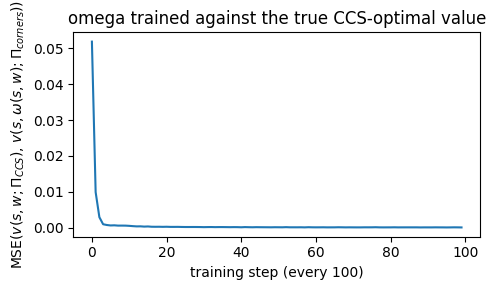

In [135]:
class SimplexMetaPolicy(nn.Module):
    """Same role as MetaPolicy (omega(s, w) -> a vector in R^d), but projects onto the
    probability simplex (z >= 0, sum(z) = 1) via softmax instead of onto the unit L2
    sphere -- z is meant to be read as a weight vector, the same kind of object as w."""

    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + task_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, task_dim),
        )

    def forward(self, s, w):
        logits = self.net(torch.cat([s, w], dim=-1))
        return F.softmax(logits, dim=-1)


def gather_psi_matrix(state, sf_tables):
    """Stack every (policy, action) SF vector at `state` into one (n_tables * n_actions, d)
    matrix -- the finite set of linear functionals of z that v(s, .; sf_tables) maxes over."""
    return np.concatenate([sft[state] for sft in sf_tables], axis=0)


states_pool_ccs = sorted(set().union(*(pi.table.keys() for pi in Pi_CCS)))
print(f"{len(states_pool_ccs)} distinct states visited across the {len(Pi_CCS)} CCS policies")


def train_omega_against_ccs(target_sf_tables, predict_sf_tables, states_pool, omega,
                             task_dim, num_steps=10_000, batch_size=256, lr=1e-3, seed=0):
    """Regress omega against the TRUE optimal value (target_sf_tables = Pi_CCS), while the
    prediction is still evaluated through the SMALL deployed base set
    (predict_sf_tables = Pi_corners) -- the actual claim under test: a small base policy set
    + a trained meta-policy should reach full-CCS optimality. No environment interaction, no
    critic network, no bootstrapping -- see markdown above."""
    rng = np.random.default_rng(seed)
    opt = torch.optim.Adam(omega.parameters(), lr=lr)
    losses = []
    for t in range(num_steps):
        idx = rng.integers(0, len(states_pool), size=batch_size)
        states = [states_pool[i] for i in idx]
        target_psi = np.stack([gather_psi_matrix(s, target_sf_tables) for s in states]).astype(np.float32)
        predict_psi = np.stack([gather_psi_matrix(s, predict_sf_tables) for s in states]).astype(np.float32)
        obs_batch = np.stack([office_env._normalize(s) for s in states]).astype(np.float32)
        w_batch = rng.dirichlet(np.ones(task_dim), size=batch_size).astype(np.float32)

        target_psi_t = torch.as_tensor(target_psi)     # (B, |Pi_CCS|*4, d) -- fixed, no grad
        predict_psi_t = torch.as_tensor(predict_psi)     # (B, |Pi_corners|*4, d) -- fixed, no grad
        w_t = torch.as_tensor(w_batch)                    # (B, d)
        obs_t = torch.as_tensor(obs_batch)                # (B, 2)

        with torch.no_grad():
            target = torch.bmm(target_psi_t, w_t.unsqueeze(-1)).squeeze(-1).max(dim=1).values

        z = omega(obs_t, w_t)                               # (B, d), simplex-valued already
        pred = torch.bmm(predict_psi_t, z.unsqueeze(-1)).squeeze(-1).max(dim=1).values

        loss = F.mse_loss(pred, target)
        opt.zero_grad()
        loss.backward()
        opt.step()

        if t % 100 == 0:
            losses.append(loss.item())
    return omega, losses


torch.manual_seed(SEED)
omega_ccs_supervised = SimplexMetaPolicy(state_dim, d)

omega_ccs_supervised, ccs_supervised_losses = train_omega_against_ccs(
    Pi_CCS, Pi_corners, states_pool_ccs, omega_ccs_supervised, task_dim=d, num_steps=10_000, seed=SEED,
)

plt.figure(figsize=(5, 3))
plt.plot(ccs_supervised_losses)
plt.xlabel("training step (every 100)")
plt.ylabel(r"MSE($v(s,w;\Pi_{CCS})$, $v(s,\omega(s,w);\Pi_{corners})$)")
plt.title("omega trained against the true CCS-optimal value")
plt.tight_layout()
plt.show()

Evaluate the same way as before -- real greedy rollouts, scalarized by `w` -- on the
same 5 test weights, now with a properly principled ground-truth column: `gpi_over_full_ccs`
(GPI over all of `Pi_CCS`, i.e. the actual optimal value for `w`) replaces the earlier
per-weight `fresh_solve` retraining, since the real CCS is already trained above.

In [136]:
py_rng_eval3 = random.Random(SEED + 3000)

rows_ccs_supervised = []
for w in test_weights:
    gpi_corners_fn = lambda state, obs, w=w: gpi_action(py_rng_eval3, state, w, Pi_corners)
    gpi_ccs_fn = lambda state, obs, w=w: gpi_action(py_rng_eval3, state, w, Pi_CCS)
    omega_fn = lambda state, obs, w=w: ok_policy_action(py_rng_eval3, state, obs, w, omega_ccs_supervised, Pi_corners)

    rows_ccs_supervised.append(dict(
        w=np.round(w, 3),
        gpi_over_corners=mean_value(office_env, gpi_corners_fn, w, starts),
        omega_ccs_supervised=mean_value(office_env, omega_fn, w, starts),
        gpi_over_full_ccs=mean_value(office_env, gpi_ccs_fn, w, starts),
    ))

ccs_supervised_df = pd.DataFrame(rows_ccs_supervised)
ccs_supervised_df["gap"] = ccs_supervised_df["gpi_over_full_ccs"] - ccs_supervised_df["omega_ccs_supervised"]
display(ccs_supervised_df)
print(f"mean |gap| = {ccs_supervised_df['gap'].abs().mean():.4f}")

,w,gpi_over_corners,omega_ccs_supervised,gpi_over_full_ccs,gap
0,"[0.161, 0.031, 0.068, 0.083, 0.025, 0.633]",0.421817,0.054809,0.178068,0.123259
1,"[0.611, 0.022, 0.071, 0.118, 0.127, 0.052]",0.329751,0.077855,0.171919,0.094065
2,"[0.326, 0.094, 0.152, 0.162, 0.238, 0.029]",0.175032,0.106953,0.091687,-0.015266
3,"[0.115, 0.063, 0.086, 0.132, 0.349, 0.255]",0.231173,0.087316,0.141884,0.054568
4,"[0.073, 0.007, 0.309, 0.276, 0.199, 0.137]",0.285372,0.182457,0.285372,0.102916


mean |gap| = 0.0780


### Algorithm 2 (OK-LS) and Algorithm 1, lines 5-18: the real OKB outer loop

Two more pieces of pseudocode to place, both from `OKB/NeurIPS-2025-...pdf`, p.5:

```
Algorithm 2: OK-Linear Support (OK-LS)
Input: Meta-policy ω, partial CCS Ψ^OK, weight support W^sup, base policies Π_k.
1  while True do
2    W^corner ← CornerW(Ψ^OK) \ W^sup
3    if W^cw is empty then
4        return ω, Ψ^OK, W^sup
5    W^sup ← W^sup ∪ W^corner
6    ω ← TrainOK(ω, W^sup, Π_k)                      ▷ (Alg. 3)
7    Ψ^OK ← {ψ^{π^OK_ω(·,w;Π_k)} | w ∈ W^sup}
8    Ψ^OK ← RemoveDominated(Ψ^OK)
```

```
Algorithm 1 (OKB), lines 5-18:
5  for k = 0, 1, 2, ... do
     ▷ Update meta-policy ω
6    ω_{k+1}, Ψ_{k+1}^OK, W_{k+1}^sup ← OK-LS(ω_k, Ψ_k^OK, W_k^sup, Π_k)
7    C ← {}
     ▷ Check if task w is solvable with OK and Π_k
8    for w ∈ CornerW(Ψ_k^base ∪ Ψ_k^OK) do
9      if π*_w is not in Π^OK(Π_k) then
10       C ← C ∪ {w}
11   if C is empty then
       ▷ Found optimal basis Π and meta-policy ω
12     return ω_{k+1}, Π_k, Ψ_{k+1}^OK
13   else
       ▷ Learn a new base policy
14     w ← select a task from C
15     π_w, ψ^π_w ← NewPolicy(w)
16     Π_{k+1} ← Π_k ∪ {π_w}
17     Ψ_{k+1}^base ← Ψ_k^base ∪ {ψ^π_w}
18     Π_{k+1}, Ψ_{k+1}^base ← RemoveDominated(Π_{k+1}, Ψ_{k+1}^base)
```

Three helpers these need, built directly on top of what already exists:

- **`CornerW(Ψ)`**: exactly the corner-weight machinery already used for the ground-truth
  CCS above (`OLS.corner_weights_new()`/`extrema_weights()`) -- it only needs a list of SF
  vectors, so a throwaway `OLS` instance with `.ccs` set to `Ψ` computes it directly, no
  reimplementation needed.
- **`RemoveDominated(Ψ)`**: the paper's version drops any policy that is never *uniquely*
  needed to represent the CCS. Here it's approximated as "keep whichever vectors are the
  argmax for at least one of the set's own corner weights" -- exact CCS-domination checking
  needs more bookkeeping (`OLS.is_dominated`'s `self.W` history) than is worth adding for
  a basis this small, and this test is still a real, checkable pruning criterion.
- **Evaluating $\psi^{\pi^{\text{OK}}_\omega(\cdot,w;\Pi_k)}$ (line 7)**: Office is
  deterministic given a fixed start state and $\omega$ is evaluated greedily (no
  exploration noise), so a *single* rollout per initial state is the exact expectation,
  not an estimate -- same principle as `expected_sf`, generalized from the tabular policy
  to the OK policy (reusing `ok_policy_action` from the TrainOK validation cell above).

One deliberate simplification for line 9's optimality check, flagged plainly: the paper's
actual test (Thm. 4.2, App. E) verifies optimality *without* a ground-truth CCS, using the
advantage function $A_r^{\omega}(s,a)$ estimated from replay-buffer samples -- because
avoiding the need for a full CCS is the entire point of OKB. Here, uniquely, we already
computed a full CCS above purely to have a ground truth to validate against, so line 9 is
implemented as a direct comparison: "OK's current best value at $w$" (evaluated by
actually querying $\omega(\cdot,w)$, not looked up from stale training data) vs. the true
CCS-optimal value at $w$ (`ols.max_scalarized_value(w)`). This makes the check exact rather
than heuristic, but only because ground truth happens to be available here for validation
purposes -- a real large-scale run would use the paper's advantage-based test instead.

In [ ]:
def corner_weights(psi_vectors):
    """CornerW(Psi) (Alg. 1 line 8, Alg. 2 line 2): corner weights of the convex upper
    envelope of a set of SF vectors, via the same pycddlib machinery used for the ground-
    truth CCS above. Empty input -> the simplex's own corners, matching OLS.__init__'s
    own bootstrapping convention (see the CCS cell above: the first d calls to next_w()
    just return the extrema weights, before any CCS member exists to take corners of)."""
    tmp = OLS(m=d)
    if len(psi_vectors) == 0:
        return tmp.extrema_weights()
    tmp.ccs = list(psi_vectors)
    return tmp.corner_weights_new()


def remove_dominated(psi_list):
    """RemoveDominated(Psi) (Alg. 1 line 18, Alg. 2 line 8): keep only vectors that are the
    argmax for at least one of the set's own corner weights -- see markdown above for why
    this (rather than full CCS-domination bookkeeping) is enough at this scale."""
    if len(psi_list) <= 1:
        return list(range(len(psi_list)))
    corners = corner_weights(psi_list)
    arr = np.stack(psi_list)
    keep = sorted({int(np.argmax(arr @ w)) for w in corners})
    return keep


def evaluate_ok_policy(env, omega, w, Pi_base, initial_states, gamma=GAMMA, max_steps=200, seed=0):
    """psi^{pi^OK_omega(.,w;Pi_k)} (Eq. 2, Alg. 2 line 7): exact greedy rollout of the OK
    policy (z=omega(s,w), no exploration noise) from each initial state -- exact, not an
    estimate, since office_env is deterministic given a fixed start and the policy here is
    deterministic too. Reuses ok_policy_action, defined in the TrainOK validation cell."""
    rng = random.Random(seed)
    vecs = []
    for s0 in initial_states:
        obs, _ = env.reset(options={"state": tuple(s0)})
        state = tuple(env.core.state)
        total = np.zeros(env.reward_dim, dtype=np.float64)
        discount = 1.0
        for _ in range(max_steps):
            action = ok_policy_action(rng, state, obs, w, omega, Pi_base)
            obs, phi, terminated, truncated, _ = env.step(action)
            state = tuple(env.core.state)
            total = total + discount * phi
            discount *= gamma
            if terminated or truncated:
                break
        vecs.append(total)
    return np.mean(vecs, axis=0)

In [ ]:
def ok_ls(env, omega, psi_omega, W_OK, Psi_OK, W_sup, Pi_base, max_ls_iterations=6,
          train_steps=NUM_STEPS_PER_POLICY, seed=SEED):
    """Algorithm 2 (OK-LS). W_sup only ever grows (it's the meta-policy's full training
    history, kept to avoid catastrophic forgetting across calls -- App. F); (W_OK, Psi_OK)
    is the separately-pruned frontier used purely to compute the next round of corner
    weights (line 8's RemoveDominated acts on Psi^OK, not on W^sup itself)."""
    for _ in range(max_ls_iterations):
        candidates = corner_weights(Psi_OK)                                    # line 2
        W_corner = [w for w in candidates
                    if not any(np.allclose(w, w_old, atol=1e-4) for w_old in W_sup)]
        if len(W_corner) == 0:                                                 # line 3-4
            break
        W_sup = W_sup + W_corner                                               # line 5
        omega, psi_omega, _ = train_ok(env, omega, psi_omega, W_sup, Pi_base,
                                        num_steps=train_steps, seed=seed)       # line 6
        W_OK = list(W_sup)
        Psi_OK = [evaluate_ok_policy(env, omega, w, Pi_base, env.core.initial)
                  for w in W_OK]                                               # line 7
        keep = remove_dominated(Psi_OK)                                        # line 8
        W_OK = [W_OK[i] for i in keep]
        Psi_OK = [Psi_OK[i] for i in keep]
    return omega, psi_omega, W_OK, Psi_OK, W_sup


def okb_outer_loop(env, Pi_base, Psi_base, W_exp, omega, psi_omega, ols_reference,
                    max_outer_iterations=8, ok_ls_iterations=6,
                    train_steps=NUM_STEPS_PER_POLICY, solve_epsilon=0.02, seed=SEED):
    """Algorithm 1 (OKB), lines 5-18. `ols_reference` is the ground-truth CCS computed
    above -- used only for line 9's optimality check (see markdown: a simplification made
    possible because ground truth happens to be available here for validation)."""
    W_OK, Psi_OK, W_sup = [], [], []
    history = []

    for k in range(max_outer_iterations):
        omega, psi_omega, W_OK, Psi_OK, W_sup = ok_ls(
            env, omega, psi_omega, W_OK, Psi_OK, W_sup, Pi_base,
            max_ls_iterations=ok_ls_iterations, train_steps=train_steps, seed=seed)  # line 6

        candidates = corner_weights(Psi_base + Psi_OK)                         # line 8
        C = []
        for w in candidates:
            ok_value = evaluate_ok_policy(env, omega, w, Pi_base, env.core.initial)
            ok_scalar = np.dot(ok_value, w)
            css_value = ols_reference.max_scalarized_value(w)
            if css_value is not None and ok_scalar < css_value - solve_epsilon:  # line 9
                C.append((css_value - ok_scalar, w))

        history.append(dict(k=k, n_base=len(Pi_base), n_sup=len(W_sup), n_unsolved=len(C)))
        print(f"[outer k={k}] |Pi_k|={len(Pi_base)}  |W_sup|={len(W_sup)}  "
              f"unsolved corner weights: {len(C)}")

        if len(C) == 0:                                                        # line 11-12
            print("Converged: OK already matches the CCS at every corner weight checked.")
            break

        C.sort(key=lambda t: t[0], reverse=True)                               # line 14: worst gap first
        w_new = C[0][1]
        print(f"  -> training a new base policy for w={np.round(w_new, 3)} "
              f"(gap={C[0][0]:.4f})")
        pi_w, psi_w = new_policy(env, w_new, num_steps=train_steps, seed=seed)  # line 15
        Pi_base = Pi_base + [pi_w]                                             # line 16
        Psi_base = Psi_base + [psi_w]                                          # line 17
        W_exp = W_exp + [w_new]
        keep = remove_dominated(Psi_base)                                      # line 18
        Pi_base = [Pi_base[i] for i in keep]
        Psi_base = [Psi_base[i] for i in keep]
        W_exp = [W_exp[i] for i in keep]

    return Pi_base, Psi_base, W_exp, omega, psi_omega, W_OK, Psi_OK, W_sup, history

In [ ]:
torch.manual_seed(SEED)
omega_okb = MetaPolicy(state_dim, d)
psi_omega_okb = MetaCritic(state_dim, d)

Pi_base, Psi_base, W_exp, omega_okb, psi_omega_okb, W_OK, Psi_OK, W_sup, history = okb_outer_loop(
    office_env, Pi_base, Psi_base, W_exp, omega_okb, psi_omega_okb, ols,
    max_outer_iterations=6, ok_ls_iterations=4, train_steps=NUM_STEPS_PER_POLICY,
    solve_epsilon=0.02, seed=SEED,
)

print(f"\n=== OKB finished ===")
print(f"|Pi_k| (OKB behavior basis) = {len(Pi_base)}")
print(f"|CCS| (ground truth)        = {len(CCS)}")
print(f"weights trained for base policies: {[np.round(w, 3) for w in W_exp]}")

### Does fewer base policies + OK actually match the CCS?

The claim to check (Thm. 4.3): $|\Pi_k| \le |\text{CCS}|$ while $\pi_\omega^{\text{OK}}$ is
still optimal everywhere. Test it directly on random weights across the simplex, comparing
three numbers per weight $w$:

- **CCS** -- $\max_{\psi\in\text{CCS}} \psi\cdot w$ (the true optimum, `ols.max_scalarized_value(w)`).
- **GPI(reduced)** -- plain GPI using *only* $\Pi_k$, no meta-policy at all
  ($\max_{\pi\in\Pi_k}\psi^\pi\cdot w$) -- the baseline OK is supposed to improve on.
- **OK(reduced)** -- the actual OK policy on $\Pi_k$, $\psi^{\pi_\omega^{\text{OK}}}\cdot w$
  (via `evaluate_ok_policy`, an exact rollout).

If OK is doing its job, "OK(reduced)" should track "CCS" much more closely than
"GPI(reduced)" does, using strictly fewer base policies than `|CCS|`.

In [ ]:
from rl.utils.utils import random_weights

test_weights = random_weights(d, seed=123, n=30)

rows = []
for w in test_weights:
    css_val = ols.max_scalarized_value(w)
    gpi_reduced_val = max(np.dot(psi, w) for psi in Psi_base)
    ok_reduced_val = np.dot(evaluate_ok_policy(office_env, omega_okb, w, Pi_base, office_env.core.initial), w)
    rows.append((w, css_val, gpi_reduced_val, ok_reduced_val))

for w, css_val, gpi_val, ok_val in rows:
    print(f"w={np.round(w, 3)}  CCS={css_val:.3f}  GPI(reduced)={gpi_val:.3f}  OK(reduced)={ok_val:.3f}")

gap_gpi = np.mean([css - g for _, css, g, _ in rows])
gap_ok = np.mean([css - o for _, css, _, o in rows])
print(f"\n|Pi_k| (OKB reduced basis) = {len(Pi_base)}   |CCS| (ground truth) = {len(CCS)}")
print(f"mean optimality gap, plain GPI on reduced basis: {gap_gpi:.4f}")
print(f"mean optimality gap, OK on reduced basis:        {gap_ok:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
order = np.argsort([r[1] for r in rows])
xs = np.arange(len(rows))
ax.plot(xs, [rows[i][1] for i in order], "o-", color="black", label=f"CCS (|CCS|={len(CCS)})")
ax.plot(xs, [rows[i][2] for i in order], "s--", color="crimson", label=f"GPI, reduced basis (|Pi_k|={len(Pi_base)})")
ax.plot(xs, [rows[i][3] for i in order], "^--", color="royalblue", label=f"OK, reduced basis (|Pi_k|={len(Pi_base)})")
ax.set_xlabel("test weight (sorted by CCS value)")
ax.set_ylabel("scalarized value $\\psi \\cdot w$")
ax.set_title("CCS vs. GPI vs. OK, on 30 random test weights")
ax.legend()
plt.tight_layout()
plt.show()